# Model 2: Random Forest

**Algorithm**: Random Forest  
**Type**: Ensemble of Decision Trees  
**Goal**: Improve predictions by combining multiple trees

## 1. Setup

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when, countDistinct, sum as spark_sum, lit
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml import Pipeline
from pyspark.mllib.evaluation import MulticlassMetrics
import matplotlib.pyplot as plt

spark = SparkSession.builder.appName("Model2_RandomForest").master("local[*]").getOrCreate()
spark.sparkContext.setLogLevel("WARN")
print("✓ Spark started")

26/10/17 15:06:26 WARN Utils: Your hostname, Kireetis-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 10.12.112.156 instead (on interface en0)
26/10/17 15:06:26 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/17 15:06:26 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


✓ Spark started


## 2. Load and Prepare Data

This exploratory classifier identifies whether an aggregated visitor history contains a transaction. Predictors describe browsing and cart behaviour; transaction count creates the label and is not a predictor.

For a deployable future-purchase model, calculate all features before a fixed time cutoff and label transactions after that cutoff.

In [2]:
df = spark.read.option("header", True).option("inferSchema", True).csv("../data/events.csv")

# One list drives the dataset, VectorAssembler, and importance chart.
feature_columns = [
    "view_count", "cart_count", "unique_items_viewed",
    "unique_items_carted", "active_days", "cart_to_view_ratio"
]

# Aggregate behaviour for each visitor.
visitor_features = df.groupBy("visitorid").agg(
    spark_sum(when(col("event") == "view", 1).otherwise(0)).alias("view_count"),
    spark_sum(when(col("event") == "addtocart", 1).otherwise(0)).alias("cart_count"),
    countDistinct(when(col("event") == "view", col("itemid"))).alias("unique_items_viewed"),
    countDistinct(when(col("event") == "addtocart", col("itemid"))).alias("unique_items_carted"),
    countDistinct((col("timestamp") / lit(86400000)).cast("long")).alias("active_days"),
    spark_sum(when(col("event") == "transaction", 1).otherwise(0)).alias("transaction_count")
)

visitor_features = (visitor_features
    .withColumn("cart_to_view_ratio", when(col("view_count") > 0, col("cart_count") / col("view_count")).otherwise(0.0))
    .withColumn("label", when(col("transaction_count") > 0, 1.0).otherwise(0.0))
)

model_data = visitor_features.select(*feature_columns, "label")
print(f"✓ Data prepared: {model_data.count():,} visitors")

✓ Data prepared: 1,407,580 visitors


## 3. Train-Test Split

The random split holds out visitors for a reproducible benchmark. It does not validate future-time generalisation.

In [3]:
train_data, test_data = model_data.randomSplit([0.8, 0.2], seed=42)
print(f"Training: {train_data.count():,}")
print(f"Testing:  {test_data.count():,}")

26/10/17 15:06:40 WARN GarbageCollectionMetrics: To enable non-built-in garbage collector(s) List(G1 Concurrent GC), users should configure it(them) to spark.eventLog.gcMetrics.youngGenerationGarbageCollectors or spark.eventLog.gcMetrics.oldGenerationGarbageCollectors


26/10/17 15:06:40 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:40 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:40 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:40 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:40 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:40 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:40 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:40 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:40 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:06:42 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:42 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:06:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:06:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:06:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


...

26/10/17 15:07:01 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:07:02 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:02 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:02 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:02 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:07:02 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:02 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:02 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:02 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:07:02 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:03 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


Testing:  280,885


## 4. Build Random Forest Model

**Random Forest** combines many decision trees:
- Each tree votes for a prediction
- Final prediction = majority vote
- More robust than single tree

In [4]:
# Assemble features
assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features"
)

# Resource-friendly Random Forest configuration for local execution.
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    numTrees=30,      # Number of trees
    maxDepth=6,       # Max tree depth
    seed=42
)

pipeline = Pipeline(stages=[assembler, rf])
print("✓ Pipeline created with 30 trees")

✓ Pipeline created with 30 trees


## 5. Train Model

In [5]:
print("Training Random Forest...")
model = pipeline.fit(train_data)
print("✓ Training complete!")

Training Random Forest...


26/10/17 15:07:09 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:09 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:09 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:09 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:09 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:09 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:09 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:09 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:09 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:07:09 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:09 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:07:11 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:11 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:11 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:11 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:11 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:11 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:07:12 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:07:12 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


...

26/10/17 15:08:23 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:23 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:24 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:24 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:08:24 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:24 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:08:24 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:24 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:08:24 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:24 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:24 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:24 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


✓ Training complete!


## 6. Make Predictions

In [6]:
predictions = model.transform(test_data)
predictions.select("view_count", "cart_count", "label", "prediction").show(10)

26/10/17 15:08:27 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:27 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:27 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:27 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:27 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:27 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:27 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:27 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:27 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:08:27 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:27 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:27 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:27 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:08:28 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:28 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:28 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:28 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:28 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:28 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:28 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:28 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:08:28 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:28 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:28 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:28 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:28 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:08:29 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


...

26/10/17 15:08:33 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:33 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:33 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:33 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:33 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:33 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:08:33 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:33 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:08:34 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:34 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:08:34 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:34 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:34 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:34 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:34 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


+----------+----------+-----+----------+
|view_count|cart_count|label|prediction|
+----------+----------+-----+----------+
|         0|         0|  1.0|       1.0|
|         0|         0|  1.0|       1.0|
|         0|         0|  1.0|       1.0|
|         0|         1|  0.0|       0.0|
|         0|         1|  0.0|       0.0|
|         0|         1|  0.0|       0.0|
|         0|         1|  0.0|       0.0|
|         0|         1|  0.0|       0.0|
|         0|         1|  0.0|       0.0|
|         0|         1|  0.0|       0.0|
+----------+----------+-----+----------+
only showing top 10 rows



## 7. Evaluate Performance

In [7]:
prediction_labels = predictions.select(
    col("prediction").cast("double"),
    col("label").cast("double")
)

metrics = MulticlassMetrics(prediction_labels.rdd.map(lambda row: (row[0], row[1])))

accuracy = metrics.accuracy
precision = metrics.precision(1.0)
recall = metrics.recall(1.0)
f1 = metrics.fMeasure(1.0)

print("=" * 50)
print("RANDOM FOREST PERFORMANCE")
print("=" * 50)
print(f"Accuracy:  {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print("=" * 50)

26/10/17 15:08:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:37 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:08:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:38 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:38 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:08:39 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:39 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:39 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:39 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:08:39 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:39 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:39 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:39 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:39 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:39 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:39 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:39 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:39 WARN RowBasedKeyValueBatch: Calling spill() on

26/10/17 15:08:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:43 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:43 WARN RowBasedKeyValueBatch: Calling spill() on

...

26/10/17 15:08:46 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:08:46 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:46 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


26/10/17 15:08:46 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:46 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.
26/10/17 15:08:46 WARN RowBasedKeyValueBatch: Calling spill() on RowBasedKeyValueBatch. Will not spill but return 0.


/Users/kireeti/Desktop/Projects/SparkProejct/.venv/lib/python3.10/site-packages/pyspark/sql/context.py:158: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


RANDOM FOREST PERFORMANCE
Accuracy:  0.9919 (99.19%)
Precision: 0.7308
Recall:    0.0488
F1-Score:  0.0914


## 8. Visualizations

In [8]:
cm = metrics.confusionMatrix().toArray()

### Chart 1: Confusion Matrix

**Explanation**: Shows prediction accuracy. Random Forest has much better balance - it correctly identifies more purchasers than Logistic Regression.

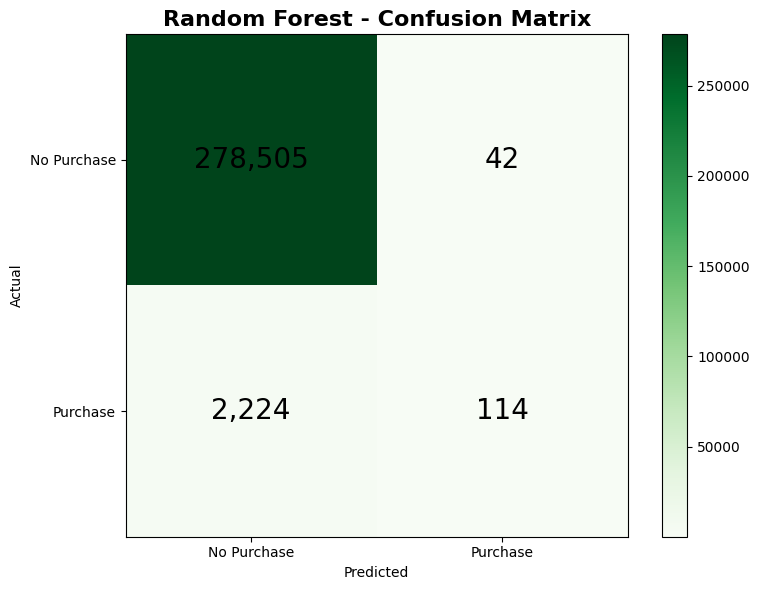

In [9]:
plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation='nearest', cmap='Greens')
plt.title('Random Forest - Confusion Matrix', fontsize=16, fontweight='bold')
plt.colorbar()
plt.xticks([0, 1], ['No Purchase', 'Purchase'])
plt.yticks([0, 1], ['No Purchase', 'Purchase'])
plt.ylabel('Actual')
plt.xlabel('Predicted')

for i in range(2):
    for j in range(2):
        plt.text(j, i, f'{int(cm[i, j]):,}', ha="center", va="center", fontsize=20)

plt.tight_layout()
plt.show()

###  Feature Importance

**Explanation**: Importance shows how much the fitted forest used each behavioural feature. It is model-specific and does not prove causation.

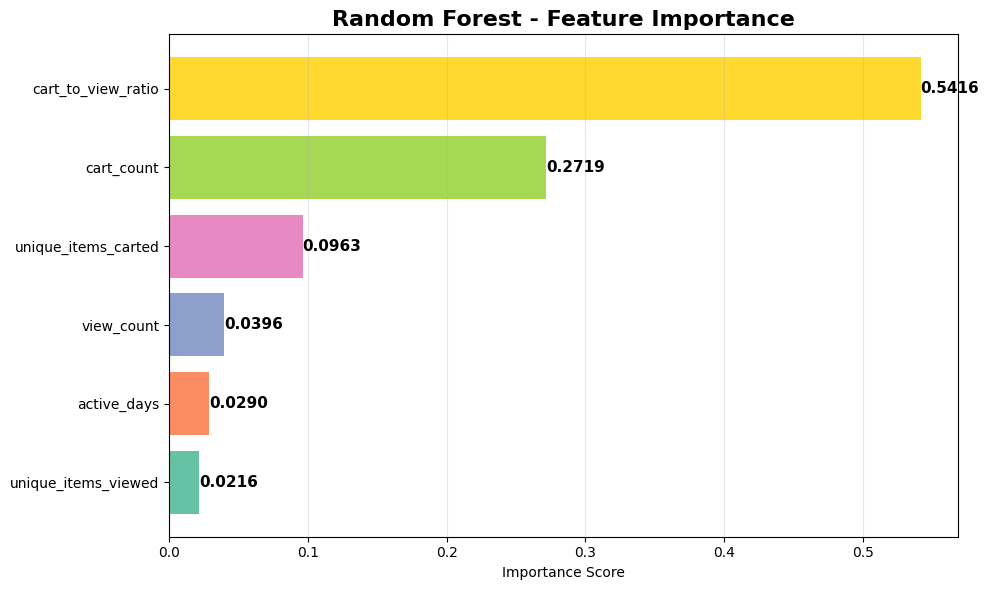


Feature Importance (highest first):
cart_to_view_ratio: 0.5416
cart_count: 0.2719
unique_items_carted: 0.0963
view_count: 0.0396
active_days: 0.0290
unique_items_viewed: 0.0216


In [10]:
# Pair each feature with the score learned by the fitted forest.
rf_model = model.stages[1]
feature_importance = sorted(
    zip(feature_columns, rf_model.featureImportances.toArray()),
    key=lambda pair: pair[1]
)
features, importances = zip(*feature_importance)

plt.figure(figsize=(10, 6))
colors = plt.cm.Set2(range(len(features)))
bars = plt.barh(features, importances, color=colors)
plt.title('Random Forest - Feature Importance', fontsize=16, fontweight='bold')
plt.xlabel('Importance Score')
plt.grid(axis='x', alpha=0.3)

# Add value labels
for bar in bars:
    width = bar.get_width()
    plt.text(width, bar.get_y() + bar.get_height()/2.,
             f'{width:.4f}',
             ha='left', va='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("\nFeature Importance (highest first):")
for feat, imp in reversed(list(zip(features, importances))):
    print(f"{feat}: {imp:.4f}")

# Current Run Metrics

**Explanation**: The chart below reports accuracy and F1-score from the current Random Forest run.

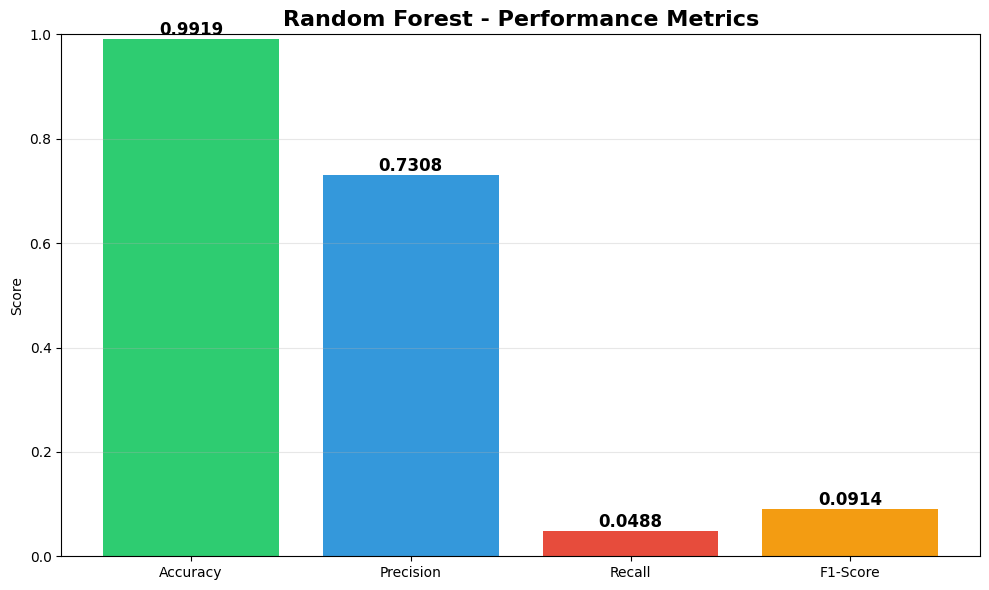

In [11]:
metrics_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Value': [accuracy, precision, recall, f1]
}

plt.figure(figsize=(10, 6))
colors = ['#2ecc71', '#3498db', '#e74c3c', '#f39c12']
bars = plt.bar(metrics_data['Metric'], metrics_data['Value'], color=colors)
plt.title('Random Forest - Performance Metrics', fontsize=16, fontweight='bold')
plt.ylabel('Score')
plt.ylim(0, 1.0)
plt.grid(axis='y', alpha=0.3)

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{height:.4f}',
             ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## 10. Stop Spark

In [12]:
spark.stop()
print("✓ Done!")

✓ Done!


---
## Summary

**Current Random Forest run:**
- Review the accuracy, precision, recall, and F1-score printed above.
- The values update whenever the notebook is re-run.
- Random Forest can capture non-linear relationships.

**How it works:**
- Multiple trees capture different patterns
- Voting mechanism reduces errors
- Can learn complex relationships

**Feature importance**: use the chart above to inspect the current fitted model.